# Storm surge — Bathtub (CLIMADA `TCSurgeBathtub`)

Empirical storm surge model applied to one ECMWF ensemble forecast. Results are read on a 15″ (~450 m) coastal grid.

For each member, the surge height comes from the maximum ECMWF wind at each cell, minus the ground elevation and an
inland decay:

`surge = 0.1023 × max(wind − 26.8, 0) + 1.83 − elevation − 0.2 × distance_to_coast_km`

**Outputs:** maximum water depth above ground per coastal cell and member, and the probability over the ensemble of
exceeding each surge threshold.

## 0. Setup

Requirements:
- GEBCO grid (GeoTIFF, 15″) covering the country, in `data/bathymetry/` (defines the coastal grid);
- NASA Earthdata login in `.env` (`EARTHDATA_USERNAME`, `EARTHDATA_PASSWORD`) for the SRTM download;
- ECMWF tropical cyclone BUFR file of the forecast cycle, in `data/bufr/` (track shown on the maps).

The first cell must run before any geospatial import.

In [1]:
# Environment: PROJ database, warnings and log messages off
import os
import sys
import logging
import warnings
from pathlib import Path

proj_dir = str(Path(sys.prefix) / "share" / "proj")
os.environ["PROJ_DATA"] = proj_dir
os.environ["PROJ_LIB"] = proj_dir
os.environ["PYTHONWARNINGS"] = "ignore"  
import pyproj
pyproj.datadir.set_data_dir(proj_dir)

warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)   # errors are still shown

In [2]:
import time
import zipfile
import contextlib
from datetime import datetime

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import shapely
import rasterio
from rasterio.features import rasterize
from rasterio.windows import from_bounds
from rasterio.warp import reproject, Resampling
from rasterio.merge import merge as rio_merge
from scipy import sparse
from dotenv import load_dotenv
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT / ".env")   # Earthdata credentials (never printed)
CONFIG = {
    "storm_name": "RAFAEL",
    "country_iso3": "CUB",
    "cycle_date": "2024-11-06",
    "cycle_time": 0,                              # 00z
    "cycle_tag": "rafael_20241106_00z_gem15",
    "forecast_steps_h": list(range(0, 49, 3)),    # 0-48 h, 3-hourly
    "bufr_file": PROJECT / "data/bufr/20241106_00z_tf.bufr",
    "bathymetry_dir": PROJECT / "data/bathymetry",
    "srtm_raw_dir": PROJECT / "data/dem/srtm_raw",
    "dem_file": PROJECT / "data/dem/CUB_gem15.tif",
    "wind_grib": PROJECT / "data/wind/ecmwf_enfo_10uv_20241106_00z_0-48h.grib2",
    "output_dir": PROJECT / "outputs/rafael_gem15",
    "grid_res_as": 15,                            # coastal output grid, arc-seconds (~450 m, GEBCO native)
    "max_elevation_m": 10,                        # coastal lowland only
    "max_dist_inland_km": 50,
    "wind_min_kt": 34,                            # below tropical-storm wind: no surge
    "inland_decay_m_per_km": 0.2,                 # CLIMADA default (Pielke & Pielke 1997)
    "sea_level_rise_m": 0.0,
    "surge_thresholds_m": [0.5, 1.0, 2.0, 3.0],
}
OUT = CONFIG["output_dir"]
MEMBERS_DIR = OUT / "members"
MEMBERS_DIR.mkdir(parents=True, exist_ok=True)
CONFIG["srtm_raw_dir"].mkdir(parents=True, exist_ok=True)
CONFIG["wind_grib"].parent.mkdir(parents=True, exist_ok=True)
TAG = CONFIG["cycle_tag"]

TIMINGS = {}

@contextlib.contextmanager
def timer(name):
    t0 = time.perf_counter()
    yield
    TIMINGS[name] = time.perf_counter() - t0
    print(f"[{name}] {TIMINGS[name]:.1f} s")

print("Earthdata login set:", bool(os.getenv("EARTHDATA_USERNAME")))

Earthdata login set: True


## 1. Coastal grid (15″, ~450 m)

One point per GEBCO cell centre, kept when the cell is on land in the country, its GEBCO elevation is above 0 and at
most 10 m, and it lies within 50 km of the coast.

In [3]:
from gigaspatial.handlers import AdminBoundaries

gebco_files = sorted(CONFIG["bathymetry_dir"].glob("*.tif"))
assert gebco_files, f"No GEBCO GeoTIFF in {CONFIG['bathymetry_dir']}"
TOPO_FILE = gebco_files[0]

with timer("1_coastal_grid"):
    country = gpd.GeoSeries(
        [AdminBoundaries.create(country_code=CONFIG["country_iso3"]).to_geoms()[0]], crs="EPSG:4326")
    west, south, east, north = country.total_bounds + np.array([-0.1, -0.1, 0.1, 0.1])

    with rasterio.open(TOPO_FILE) as src:
        assert round(src.res[0] * 3600, 1) <= CONFIG["grid_res_as"], "GEBCO grid is coarser than the requested resolution"
        win = from_bounds(west, south, east, north, src.transform).round_offsets().round_lengths()
        gebco = src.read(1, window=win).astype("float32")
        grid_transform = src.window_transform(win)
    grid_shape = gebco.shape

    on_land = rasterize([country.iloc[0]], out_shape=grid_shape, transform=grid_transform).astype(bool)
    rows, cols = np.nonzero(on_land & (gebco > 0) & (gebco <= CONFIG["max_elevation_m"]))
    lon, lat = rasterio.transform.xy(grid_transform, rows, cols, offset="center")

    points = gpd.GeoDataFrame(
        {"lon": np.asarray(lon), "lat": np.asarray(lat), "row": rows, "col": cols,
         "elevation_gebco_m": gebco[rows, cols]},
        geometry=gpd.points_from_xy(lon, lat), crs="EPSG:4326")

    utm = country.estimate_utm_crs()
    boundary_m = country.to_crs(utm).iloc[0].boundary
    points["dist_coast_km"] = points.geometry.to_crs(utm).distance(boundary_m).values / 1000
    points = points[points["dist_coast_km"] <= CONFIG["max_dist_inland_km"]].reset_index(drop=True)
    points.insert(0, "point_id", np.arange(len(points)))

half = CONFIG["grid_res_as"] / 3600 / 2
cell_km2 = (2 * half * 111.32) ** 2 * np.cos(np.radians(points["lat"].values))
print(f"{len(points)} coastal cells | {cell_km2.sum():.0f} km²")

[1_coastal_grid] 12.4 s
96336 coastal cells | 19221 km²


## 2. Elevation — SRTM 90 m

SRTM tiles are downloaded once through GigaSpatial and merged. The elevation of each 450 m cell is the mean of the SRTM
pixels on land inside the cell (about 5 × 5 pixels). Negative SRTM values on land are set to 0.

In [4]:
from gigaspatial.handlers.nasa import NasaSRTMHandler
from gigaspatial.handlers.nasa.srtm import NasaSRTMConfig

with timer("2_srtm_download"):
    if not CONFIG["dem_file"].exists():
        srtm_config = NasaSRTMConfig(
            resolution="90m",
            base_path=CONFIG["srtm_raw_dir"],
            earthdata_username=os.environ["EARTHDATA_USERNAME"],
            earthdata_password=os.environ["EARTHDATA_PASSWORD"],
        )
        area = country.iloc[0]
        NasaSRTMHandler(config=srtm_config).ensure_data_available(source=area)
        zips = [p for p in srtm_config.get_data_unit_paths(srtm_config.get_relevant_data_units(area))
                if Path(p).exists()]

        hgt_files = []
        for z in zips:
            with zipfile.ZipFile(z) as zf:
                for name in zf.namelist():
                    if name.lower().endswith(".hgt"):
                        zf.extract(name, CONFIG["srtm_raw_dir"])
                        hgt_files.append(CONFIG["srtm_raw_dir"] / name)

        sources = [rasterio.open(f) for f in hgt_files]
        mosaic, transform = rio_merge(sources)
        profile = sources[0].profile.copy()
        profile.update(driver="GTiff", height=mosaic.shape[1], width=mosaic.shape[2],
                       transform=transform, compress="deflate")
        for s in sources:
            s.close()
        with rasterio.open(CONFIG["dem_file"], "w", **profile) as dst:
            dst.write(mosaic)

[2_srtm_download] 0.0 s


In [5]:
CELL_DEM = OUT / f"{TAG}_srtm_cell_mean_{CONFIG['grid_res_as']}as.tif"

with timer("2_cell_elevation"):
    with rasterio.open(CONFIG["dem_file"]) as dem:
        w = from_bounds(west, south, east, north, dem.transform).round_offsets().round_lengths()
        srtm = dem.read(1, window=w, masked=True).astype("float32").filled(np.nan)
        srtm_transform = dem.window_transform(w)

    land3 = rasterize([country.iloc[0]], out_shape=srtm.shape, transform=srtm_transform).astype(bool)
    srtm = np.where(land3, np.clip(srtm, 0, None), np.nan)          # land pixels only, negatives -> 0

    cell_elev = np.full(grid_shape, np.nan, dtype="float32")
    reproject(srtm, cell_elev, src_transform=srtm_transform, src_crs="EPSG:4326",
              dst_transform=grid_transform, dst_crs="EPSG:4326",
              resampling=Resampling.average, src_nodata=np.nan, dst_nodata=np.nan)

    with rasterio.open(CELL_DEM, "w", driver="GTiff", height=grid_shape[0], width=grid_shape[1], count=1,
                       dtype="float32", crs="EPSG:4326", transform=grid_transform, nodata=-9999) as dst:
        dst.write(np.nan_to_num(cell_elev, nan=-9999), 1)

points["elevation_m"] = cell_elev[points["row"], points["col"]]
points.drop(columns="geometry").to_parquet(OUT / f"{TAG}_coastal_points.parquet", index=False)
e = points["elevation_m"]
print(f"Cell elevation (SRTM mean): {e.min():.1f}–{e.max():.1f} m | median {e.median():.1f} m "
      f"| cells above {CONFIG['max_elevation_m']} m: {(e > CONFIG['max_elevation_m']).sum()} | no SRTM land: {e.isna().sum()}")

[2_cell_elevation] 22.5 s
Cell elevation (SRTM mean): 0.0–52.6 m | median 6.1 m | cells above 10 m: 10341 | no SRTM land: 685


## 3. ECMWF ensemble wind

ECMWF open data, 10 m wind (`10u`/`10v`, 0.25°), control + 50 perturbed members, 0–48 h every 3 h. The archive on AWS
is used for past cycles. Wind speed = √(u² + v²), maximum over the forecast steps, interpolated (bilinear) at each cell
centre. Wind below 34 kt is set to 0.

In [6]:
from ecmwf.opendata import Client

with timer("3_wind_download"):
    if not CONFIG["wind_grib"].exists():
        Client(source="aws").retrieve(
            date=CONFIG["cycle_date"], time=CONFIG["cycle_time"], stream="enfo", type=["cf", "pf"],
            step=CONFIG["forecast_steps_h"], param=["10u", "10v"], target=str(CONFIG["wind_grib"]))
print(f"Wind GRIB: {CONFIG['wind_grib'].stat().st_size / 1e6:.0f} MB")

[3_wind_download] 0.0 s
Wind GRIB: 1469 MB


In [7]:
def read_max_wind(data_type, margin=1.0):
    """Maximum 10 m wind speed over the forecast steps, in a box around the country."""
    ds = xr.open_dataset(CONFIG["wind_grib"], engine="cfgrib",
                         backend_kwargs={"filter_by_keys": {"dataType": data_type}, "indexpath": ""})
    if float(ds.longitude.max()) > 180:
        ds = ds.assign_coords(longitude=((ds.longitude + 180) % 360) - 180).sortby("longitude")
    ds = ds.sortby("latitude").sel(latitude=slice(south - margin, north + margin),
                                   longitude=slice(west - margin, east + margin))
    speed = np.sqrt(ds["u10"] ** 2 + ds["v10"] ** 2)
    if "number" not in speed.dims:
        speed = speed.expand_dims("number") if "number" in speed.coords else speed.expand_dims(number=[0])
    return speed.max(dim="step").load()

with timer("3_wind_to_cells"):
    wind_max = xr.concat([read_max_wind("cf"), read_max_wind("pf")], dim="number").sortby("number")
    wind = wind_max.interp(latitude=xr.DataArray(points["lat"].values, dims="point"),
                           longitude=xr.DataArray(points["lon"].values, dims="point"), method="linear")
    wind_ms = np.nan_to_num(wind.transpose("number", "point").values)       # (members, cells)
    wind_ms[wind_ms < CONFIG["wind_min_kt"] * 0.514444] = 0.0

members = wind_max["number"].values.astype(int)                             # 0 = control
assert list(members) == list(range(51)), "Expected control + 50 perturbed members"
print(f"Wind: {wind_ms.shape[0]} members x {wind_ms.shape[1]} cells | max {wind_ms.max():.1f} m/s "
      f"({wind_ms.max() / 0.514444:.0f} kt)")

[3_wind_to_cells] 33.4 s
Wind: 51 members x 96336 cells | max 31.6 m/s (61 kt)


## 4. Surge — CLIMADA `TCSurgeBathtub`

The wind matrix is wrapped in a CLIMADA `Hazard` (one event per member). CLIMADA reads the cell elevation from the
cell-mean SRTM grid of section 2 and keeps cells within 50 km of the coast and between 0 and 10 m. Only the surge
height is used (`intensity`), i.e. the water depth above ground.

In [8]:
from climada.hazard import Centroids, Hazard
from climada_petals.hazard import TCSurgeBathtub

n_mem, n_pts = wind_ms.shape
centroids = Centroids(lat=points["lat"].values, lon=points["lon"].values)
_signed_dist_m = -points["dist_coast_km"].values * 1000     # inland = negative (CLIMADA convention)
centroids.get_dist_coast = lambda signed=False, precomputed=True: _signed_dist_m if signed else np.abs(_signed_dist_m)

wind_haz = Hazard(
    haz_type="TC", units="m/s", centroids=centroids,
    event_id=np.arange(1, n_mem + 1),
    event_name=[f"{CONFIG['storm_name']}_m{m:02d}" for m in members],
    frequency=np.full(n_mem, 1.0 / n_mem),
    date=np.full(n_mem, datetime.strptime(CONFIG["cycle_date"], "%Y-%m-%d").toordinal()),
    orig=np.zeros(n_mem, dtype=bool),
    intensity=sparse.csr_matrix(wind_ms),
    fraction=sparse.csr_matrix((n_mem, n_pts)),
)

with timer("4_surge_bathtub"):
    surge_haz = TCSurgeBathtub.from_tc_winds(
        wind_haz, str(CELL_DEM),
        inland_decay_rate=CONFIG["inland_decay_m_per_km"],
        add_sea_level_rise=CONFIG["sea_level_rise_m"],
    )
    depth_all = surge_haz.intensity.toarray().astype("float32")             # (members, cells), metres

for i, m in enumerate(members):
    pd.DataFrame({"point_id": points["point_id"], "member": m, "depth_m": depth_all[i]}).to_parquet(
        MEMBERS_DIR / f"{TAG}_member{m:02d}.parquet", index=False)

runs = pd.DataFrame({"member": members, "max_depth_m": depth_all.max(axis=1),
                     "flooded_cells": (depth_all > 0).sum(axis=1)})
print(f"{n_mem} members | max depth {depth_all.max():.2f} m | cells flooded in at least 1 member: "
      f"{(depth_all.max(axis=0) > 0).sum()}")

[4_surge_bathtub] 0.2 s
51 members | max depth 1.72 m | cells flooded in at least 1 member: 160


## 5. Results

Results are read from the member files.
- **Control member:** maximum water depth above ground, in classes up to 4 m.
- **Ensemble:** probability that the water depth reaches each threshold, over the members available.

In [9]:
files = sorted(MEMBERS_DIR.glob(f"{TAG}_member*.parquet"))
depth = (pd.concat([pd.read_parquet(f) for f in files])
         .pivot(index="point_id", columns="member", values="depth_m")
         .reindex(points["point_id"]).fillna(0.0))
n_members = depth.shape[1]
thresholds = CONFIG["surge_thresholds_m"]

result = points[["point_id", "lon", "lat", "elevation_m", "dist_coast_km"]].copy()
result["control_depth_m"] = depth[0].values if 0 in depth.columns else np.nan
for thr in thresholds:
    result[f"p_ge_{thr:g}m"] = (depth.values >= thr).mean(axis=1)

rows = []
for thr in thresholds:
    p = result[f"p_ge_{thr:g}m"].values
    ctrl = result["control_depth_m"].values >= thr
    rows.append({
        "threshold": f">= {thr:g} m",
        "control_cells": int(ctrl.sum()),
        "control_km2": round(float(cell_km2[ctrl].sum()), 1),
        "cells_P>0": int((p > 0).sum()),
        "cells_P>=50%": int((p >= 0.5).sum()),
    })
table = pd.DataFrame(rows)
print(f"{n_members} member(s) | control max depth: {result['control_depth_m'].max():.2f} m")
table

51 member(s) | control max depth: 0.89 m


,threshold,control_cells,control_km2,cells_P>0,cells_P>=50%
0,>= 0.5 m,1,0.2,70,1
1,>= 1 m,0,0.0,24,0
2,>= 2 m,0,0.0,0,0
3,>= 3 m,0,0.0,0,0


In [10]:
# Control track (reference on the maps)
from climada_petals.hazard.tc_tracks_forecast import TCForecast
from climada.hazard import TCTracks

fc = TCForecast()
fc.read_one_bufr_tc(str(CONFIG["bufr_file"]))
ctrl = next(t for t in fc.data if t.name.upper() == CONFIG["storm_name"]
            and bool(t.attrs["is_ensemble"]) and not 1 <= int(t.attrs["ensemble_number"]) <= 50)
ctrl_tracks = TCTracks(data=[ctrl])
ctrl_tracks.equal_timestep(time_step_h=1)    # hourly positions, as in the GeoClaw notebook
track0 = ctrl_tracks.data[0]

parts = country.explode(index_parts=False)
x0, y0, x1, y1 = parts.iloc[int(np.argmax(parts.area))].bounds    # main island only

def base_map(ax, title):
    country.plot(ax=ax, color="#eeeeee", edgecolor="#999999", linewidth=0.5)
    ax.plot(track0.lon, track0.lat, color="crimson", linewidth=1)
    ax.set_xlim(x0 - 0.1, x1 + 0.1)
    ax.set_ylim(y0 - 0.1, y1 + 0.1)
    ax.set_title(title, fontsize=10)

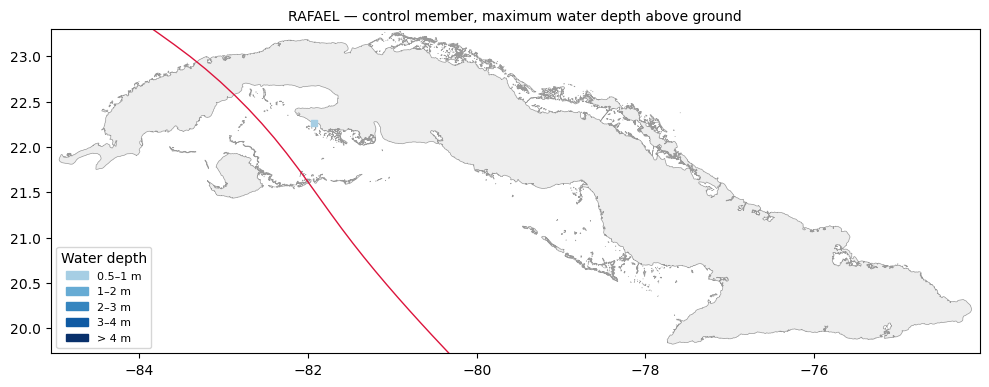

In [11]:
# Control member: water depth above ground
classes = [0.5, 1, 2, 3, 4, np.inf]
labels = ["0.5–1 m", "1–2 m", "2–3 m", "3–4 m", "> 4 m"]
cmap = ListedColormap(plt.cm.Blues(np.linspace(0.35, 1.0, len(labels))))
norm = BoundaryNorm(classes[:-1] + [classes[-2] + 1], cmap.N)

fig, ax = plt.subplots(figsize=(10, 5))
base_map(ax, f"{CONFIG['storm_name']} — control member, maximum water depth above ground")
d = result["control_depth_m"].values
wet = d >= 0.5
if wet.any():
    ax.scatter(points.lon[wet], points.lat[wet], c=np.clip(d[wet], None, 4.5),
               cmap=cmap, norm=norm, s=14, marker="s")
handles = [plt.Rectangle((0, 0), 1, 1, color=cmap(i)) for i in range(len(labels))]
ax.legend(handles, labels, title="Water depth", loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig(OUT / f"{TAG}_control_depth.png", dpi=150)
plt.show()

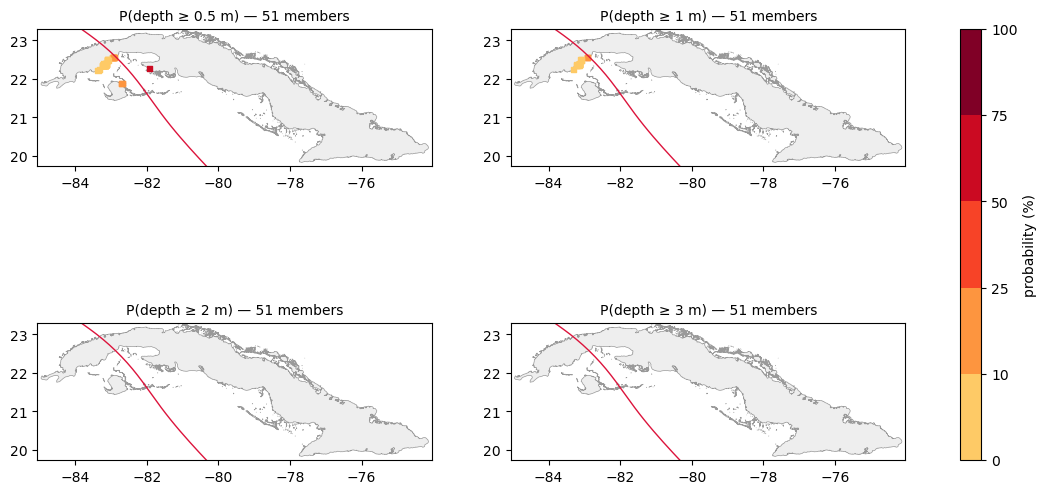

In [12]:
# Ensemble: probability of reaching each threshold
if n_members < 2:
    print("Probability maps need at least 2 members.")
else:
    p_bins = [0, 10, 25, 50, 75, 100]
    p_cmap = ListedColormap(plt.cm.YlOrRd(np.linspace(0.3, 1.0, len(p_bins) - 1)))
    p_norm = BoundaryNorm(p_bins, p_cmap.N)

    fig, axes = plt.subplots(2, 2, figsize=(14, 7))
    for ax, thr in zip(axes.flat, thresholds):
        p = result[f"p_ge_{thr:g}m"].values * 100
        hit = p > 0
        base_map(ax, f"P(depth ≥ {thr:g} m) — {n_members} members")
        ax.scatter(points.lon[hit], points.lat[hit], c=p[hit], cmap=p_cmap, norm=p_norm, s=14, marker="s")
    fig.colorbar(plt.cm.ScalarMappable(norm=p_norm, cmap=p_cmap), ax=axes, shrink=0.8,
                 label="probability (%)", ticks=p_bins)
    plt.savefig(OUT / f"{TAG}_probability.png", dpi=150, bbox_inches="tight")
    plt.show()

## 6. Outputs and runtime

Downloads (SRTM, wind) happen once. The compute per forecast cycle is the wind on the cells and the surge.

In [13]:
result.to_parquet(OUT / f"{TAG}_ensemble_summary.parquet", index=False)
runs.to_csv(OUT / f"{TAG}_runs.csv", index=False)

timings = pd.Series(TIMINGS, name="seconds").round(1)
compute = timings[["3_wind_to_cells", "4_surge_bathtub"]].sum()
print(timings.to_string())
print(f"\nCompute per cycle (wind to cells + surge): {compute:.0f} s for {n_pts} cells x {n_mem} members")
timings.to_csv(OUT / f"{TAG}_timings.csv")

1_coastal_grid      12.4
2_srtm_download      0.0
2_cell_elevation    22.5
3_wind_download      0.0
3_wind_to_cells     33.4
4_surge_bathtub      0.2

Compute per cycle (wind to cells + surge): 34 s for 96336 cells x 51 members
